<a href="https://colab.research.google.com/github/Tanisha-dey18/small-project/blob/main/AIML2%263.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install ucimlrepo

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
student_performance = fetch_ucirepo(id=320)

X = student_performance.data.features.copy()
y = student_performance.data.targets.copy()

df = pd.concat([X, y], axis=1)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully.
Shape: (649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [ ]:

print("Data Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

Data Types:
school        object
sex           object
age            int64
address       object
famsize       object
Pstatus       object
Medu           int64
Fedu           int64
Mjob          object
Fjob          object
reason        object
guardian      object
traveltime     int64
studytime      int64
failures       int64
schoolsup     object
famsup        object
paid          object
activities    object
nursery       object
higher        object
internet      object
romantic      object
famrel         int64
freetime       int64
goout          int64
Dalc           int64
Walc           int64
health         int64
absences       int64
G1             int64
G2             int64
G3             int64
dtype: object

Missing Values:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup  

In [ ]:
duplicate_count = df.duplicated().sum()
print("Number of duplicate rows:", duplicate_count)

df = df.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", df.shape)

Number of duplicate rows: 0
Shape after removing duplicates: (649, 33)


In [ ]:
numerical_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical columns:")
print(numerical_cols)

print("\nCategorical columns:")
print(categorical_cols)

Numerical columns:
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Categorical columns:
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


In [ ]:
target = 'G3'

X = df.drop(columns=[target])
y = df[target]

X_encoded = pd.get_dummies(
    X,
    columns=X.select_dtypes(exclude=np.number).columns,
    drop_first=True
)

print("Original feature count:", X.shape[1])
print("Feature count after encoding:", X_encoded.shape[1])

X_encoded.head()

Original feature count: 32
Feature count after encoding: 41


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,guardian_mother,guardian_other,schoolsup_yes,famsup_yes,paid_yes,activities_yes,nursery_yes,higher_yes,internet_yes,romantic_yes
0,18,4,4,2,2,0,4,3,4,1,...,True,False,True,False,False,False,True,True,False,False
1,17,1,1,1,2,0,5,3,3,1,...,False,False,False,True,False,False,False,True,True,False
2,15,1,1,1,2,0,4,3,2,2,...,True,False,True,False,False,False,True,True,True,False
3,15,4,2,1,3,0,3,2,2,1,...,True,False,False,True,False,True,True,True,True,True
4,16,3,3,1,2,0,4,3,2,1,...,False,False,False,True,False,False,True,True,False,False


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.20, random_state=42
)

print("Training set:", X_train.shape)
print("Testing set :", X_test.shape)

Training set: (519, 41)
Testing set : (130, 41)


In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X_test.columns,
    index=X_test.index
)

print("Scaling completed successfully.")
print("\nBefore scaling:")
print(X_train.iloc[:, :5].head())

print("\nAfter scaling:")
print(X_train_scaled.iloc[:, :5].head())

Scaling completed successfully.

Before scaling:
     age  Medu  Fedu  traveltime  studytime
332   18     2     2           1          3
29    16     4     4           1          2
302   18     3     2           1          3
286   17     2     1           1          1
554   17     1     1           2          1

After scaling:
          age      Medu      Fedu  traveltime  studytime
332  0.987932 -0.437418 -0.256337   -0.754310   1.352962
29  -0.629534  1.350140  1.591423   -0.754310   0.121054
302  0.987932  0.456361 -0.256337   -0.754310   1.352962
286  0.179199 -0.437418 -1.180216   -0.754310  -1.110853
554  0.179199 -1.331196 -1.180216    0.555011  -1.110853


In [ ]:
print("G1 present in features:", 'G1' in X_encoded.columns)
print("G2 present in features:", 'G2' in X_encoded.columns)
print("G3 used as target     :", target)

print("\nTeaching point:")
print("G1 and G2 are earlier-period grades, while G3 is the final grade.")
print("Using variables unavailable at prediction time can cause data leakage.")

G1 present in features: True
G2 present in features: True
G3 used as target     : G3

Teaching point:
G1 and G2 are earlier-period grades, while G3 is the final grade.
Using variables unavailable at prediction time can cause data leakage.


In [ ]:
print("Shape of final prepared dataset:", X_encoded.shape)
print("X_train shape:", X_train_scaled.shape)
print("X_test shape:", X_test_scaled.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)
print("Target variable:", target)

print("Preprocessing completed successfully.")

Shape of final prepared dataset: (649, 41)
X_train shape: (519, 41)
X_test shape: (130, 41)
Training labels: (519,)
Testing labels: (130,)
Target variable: G3
Preprocessing completed successfully.


In [ ]:
print('FINAL DATA PREPARATION SUMMARY')
print('-' * 40)

print('Original dataset shape :', df.shape)
print('Encoded feature count  :', X_encoded.shape[1])
print('Training samples       :', X_train_scaled.shape[0])
print('Testing samples        :', X_test_scaled.shape[0])
print('Missing values         :', X_encoded.isnull().sum().sum())
print('Scaling                : StandardScaler')
print('Target variable        :', target)

print('Experiment 2 completed successfully.')

FINAL DATA PREPARATION SUMMARY
----------------------------------------
Original dataset shape : (649, 33)
Encoded feature count  : 41
Training samples       : 519
Testing samples        : 130
Missing values         : 0
Scaling                : StandardScaler
Target variable        : G3
Experiment 2 completed successfully.


In [ ]:
linear_model = LinearRegression()
linear_model.fit(X_train_scaled, y_train)
y_pred = linear_model.predict(X_test_scaled)
print("First 10prediction: ", np.round(y_pred[:10], 2))

First 10prediction:  [18.4  11.83 18.56 10.81 11.74 16.52 17.69  9.21 10.99 10.53]


In [ ]:
mae= mean_absolute_error(y_test, y_pred)
mse= mean_squared_error(y_test, y_pred)
rmse= np.sqrt(mse)
r2=r2_score(y_test, y_pred)

print("Linear Regression Performance")
print("-" * 35)
print("MAE:", round(mae,3))
print("MSE:", round(mse,3))
print("RMSE:", round(rmse,3))
print("R2:", round(r2,3))

Linear Regression Performance
-----------------------------------
MAE: 0.765
MSE: 1.476
RMSE: 1.215
R2: 0.849


In [ ]:
results = pd.DataFrame({
    "Actual G3": y_test.values,
    "Predicated G3": np.round(y_pred, 2),
    "Residual": np.round(y_test.values - y_pred, 2)
})

results.head(10)

,Actual G3,Predicated G3,Residual
0,19,18.40,0.60
1,12,11.83,0.17
2,18,18.56,-0.56
3,11,10.81,0.19
4,11,11.74,-0.74
5,17,16.52,0.48
6,18,17.69,0.31
7,8,9.21,-1.21
8,10,10.99,-0.99
9,11,10.53,0.47


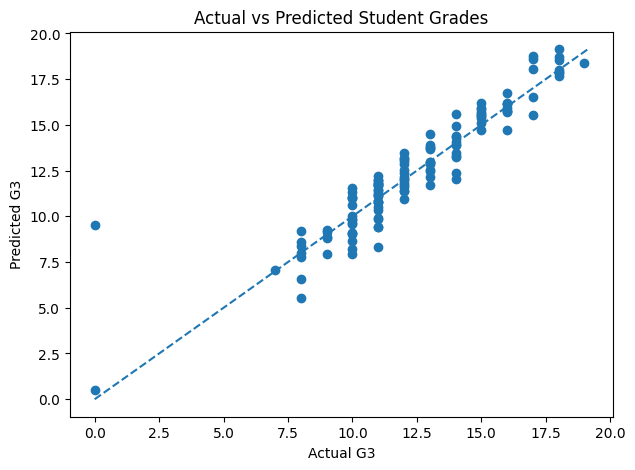

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual G3")
plt.ylabel("Predicted G3")
plt.title("Actual vs Predicted Student Grades")
plt.show()

In [ ]:
residuals = y_test.values - y_pred

print("First 10 residuals:")
print(np.round(residuals[:10], 2))

First 10 residuals:
[ 0.6   0.17 -0.56  0.19 -0.74  0.48  0.31 -1.21 -0.99  0.47]


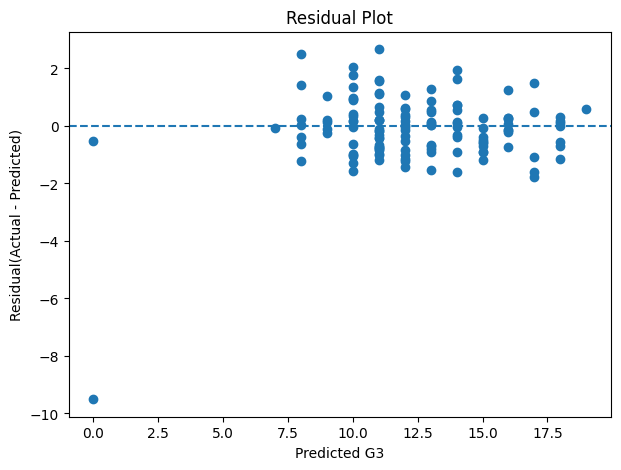

In [ ]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test, residuals)
plt.axhline(0, linestyle="--")

plt.xlabel("Predicted G3")
plt.ylabel("Residual(Actual - Predicted)")
plt.title("Residual Plot")
plt.show()

In [ ]:
coefficients = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": linear_model.coef_
})

print("Largest positive coefficients:")
print(coefficients.sort_values("Coefficient", ascending=False).head(5))

print("\nLargest negative coefficients:")
print(coefficients.sort_values("Coefficient").head(5))

Largest positive coefficients:
          Feature  Coefficient
14             G2     2.471735
13             G1     0.460262
22  Mjob_services     0.105152
23   Mjob_teacher     0.090882
20    Mjob_health     0.084867

Largest negative coefficients:
          Feature  Coefficient
26  Fjob_services    -0.240538
1            Medu    -0.166254
25     Fjob_other    -0.163351
15      school_MS    -0.145509
29   reason_other    -0.128880


In [ ]:
X_without_grades = X_encoded.drop(columns=["G1", "G2"])

X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X_without_grades,
    y,
    test_size=0.20,
    random_state=42
)

scaler2 = StandardScaler()

X_train2_scaled = scaler2.fit_transform(X_train2)
X_test2_scaled = scaler2.transform(X_test2)

model_without_grades = LinearRegression()

model_without_grades.fit(X_train2_scaled, y_train2)

y_pred2 = model_without_grades.predict(X_test2_scaled)

mae2 = mean_absolute_error(y_test2, y_pred2)

rmse2 = np.sqrt(mean_squared_error(y_test2, y_pred2))

r2_2 = r2_score(y_test2, y_pred2)

comparison_grades = pd.DataFrame({
    "Feature Set": ["With G1 + G2", "Without G1 + G2"],
    "MAE": [mae, mae2],
    "RMSE": [rmse, rmse2],
    "R²": [r2, r2_2]
})

comparison_grades

,Feature Set,MAE,RMSE,R²
0,With G1 + G2,0.765060,1.21487,0.848651
1,Without G1 + G2,2.156382,2.86178,0.160170


In [ ]:
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train_scaled, y_train)

ridge_pred = ridge_model.predict(X_test_scaled)

ridge_mae = mean_absolute_error(y_test, ridge_pred)
ridge_mse = mean_squared_error(y_test, ridge_pred)
ridge_rmse = np.sqrt(ridge_mse)
ridge_r2 = r2_score(y_test, ridge_pred)

print("Ridge Regression Performance")
print("-" * 35)
print("MAE :", round(ridge_mae, 3))
print("MSE :", round(ridge_mse, 3))
print("RMSE:", round(ridge_rmse, 3))
print("R²  :", round(ridge_r2, 3))

Ridge Regression Performance
-----------------------------------
MAE : 0.765
MSE : 1.476
RMSE: 1.215
R²  : 0.849


In [ ]:
final_comparison = pd.DataFrame({


"Model": ["Linear Regression", "Ridge Regression"],

"MAE": [mae, ridge_mae],

"MSE": [mse, ridge_mse],

"RMSE": [rmse, ridge_rmse],

"R2": [r2, ridge_r2]
 })
final_comparison

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,0.765060,1.475909,1.214870,0.848651
1,Ridge Regression,0.765009,1.475518,1.214709,0.848691
